# Evaluación Parcial N.º 1 — Fundamentos de Deep Learning
## Predicción de contratación de depósito a plazo con un MLP (Bank Marketing)

**Asignatura:** DLY0100 — Deep Learning
**Estudiante:** Tomás Benjamín Suárez Alvarado

### 1. Introducción

Un banco portugués realizó campañas de marketing telefónico para ofrecer un **depósito a plazo**. El problema es de **clasificación binaria**: dado el perfil de un cliente y su historial de contactos, predecir si contratará (`y = yes`) o no (`y = no`).

**Objetivo:** implementar un Perceptrón Multicapa (MLP) con TensorFlow/Keras, analizar mediante **experimentos controlados** (un parámetro a la vez) el efecto de activación, pérdida, tasa de aprendizaje, batch, épocas, arquitectura y regularización, ajustar los hiperparámetros con base en la evidencia y evaluar el modelo final con Accuracy, Precision, Recall y F1-Score.


## 2. Librerías y reproducibilidad

`pandas`/`numpy` para datos, `scikit-learn` para partición, preprocesamiento y métricas, `TensorFlow/Keras` para el MLP. Se fija una semilla global (`42`); además, cada entrenamiento reinicia su semilla para que los experimentos sean comparables entre sí.

In [1]:
import random
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, BatchNormalization, Activation
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)
from IPython.display import display

SEMILLA = 42

def fijar_semilla(s):
    random.seed(s); np.random.seed(s); tf.keras.utils.set_random_seed(s)

fijar_semilla(SEMILLA)

# Paleta apta para daltonismo (Okabe-Ito) y estilo de gráficos
COLORES = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 100,
                     "axes.prop_cycle": plt.cycler(color=COLORES)})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 3. Carga de datos

Se lee `bank_marketing.csv` (separado por comas). Se eliminan espacios en nombres de columnas y textos para evitar categorías duplicadas por formato.

In [2]:
ARCHIVO = "bank_marketing.csv"
if not Path(ARCHIVO).exists():
    try:
        from google.colab import files
        print("Sube el archivo bank_marketing.csv:")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Deja {ARCHIVO} en la misma carpeta del notebook.")

df = pd.read_csv(ARCHIVO)
df.columns = df.columns.str.strip()
for col in df.select_dtypes(exclude=np.number).columns:
    df[col] = df[col].astype(str).str.strip()

print(f"Dimensiones: {df.shape[0]} filas x {df.shape[1]} columnas")
display(df.head())

Sube el archivo bank_marketing.csv:


Saving bank_marketing.csv to bank_marketing.csv
Dimensiones: 45211 filas x 17 columnas


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


## 4. Exploración y calidad de los datos

Se revisan tipos, nulos, duplicados, balance de clases y valores `unknown` (texto que indica dato desconocido; no es una celda vacía).

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Nulos totales: 0 | Filas duplicadas: 0


,age,balance,day,duration,campaign,pdays,previous
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


,Cantidad,Porcentaje (%)
y,,
no,39922,88.3
yes,5289,11.7


Valores 'unknown' por columna: {'job': 288, 'education': 1857, 'contact': 13020, 'poutcome': 36959}


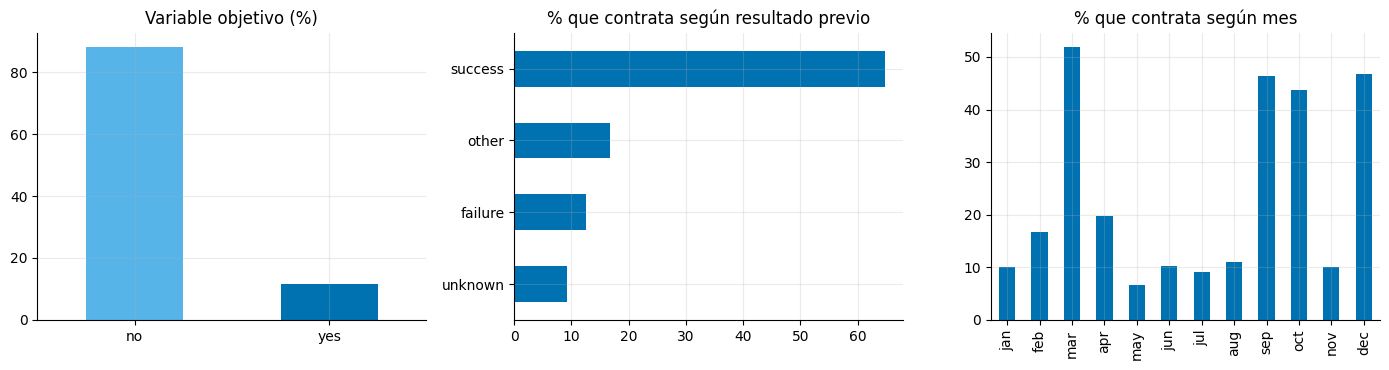

In [3]:
df.info()
print("\nNulos totales:", int(df.isna().sum().sum()), "| Filas duplicadas:", int(df.duplicated().sum()))
df = df.drop_duplicates().copy()

display(df.describe().round(2))

conteo = df["y"].value_counts().reindex(["no", "yes"], fill_value=0)
display(pd.DataFrame({"Cantidad": conteo, "Porcentaje (%)": (conteo / len(df) * 100).round(2)}))

unknown = {c: int((df[c] == "unknown").sum()) for c in df.select_dtypes(exclude=np.number).columns
           if (df[c] == "unknown").any()}
print("Valores 'unknown' por columna:", unknown)

# Tasa de contratación por segmento (justifica conservar 'unknown', 'poutcome' y 'month')
tasa = lambda col: df.groupby(col)["y"].apply(lambda s: (s == "yes").mean() * 100)
orden_meses = ["jan","feb","mar","apr","may","jun","jul","aug","sep","oct","nov","dec"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
(conteo / len(df) * 100).plot(kind="bar", ax=ax[0], color=[COLORES[5], COLORES[0]], rot=0)
ax[0].set_title("Variable objetivo (%)"); ax[0].set_xlabel("")
tasa("poutcome").sort_values().plot(kind="barh", ax=ax[1], color=COLORES[0])
ax[1].set_title("% que contrata según resultado previo"); ax[1].set_ylabel("")
tasa("month").reindex(orden_meses).plot(kind="bar", ax=ax[2], color=COLORES[0])
ax[2].set_title("% que contrata según mes"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

### Hallazgos y decisiones

- **Desbalance:** solo ≈ 11,7 % contrata. Un modelo que responda siempre `no` obtendría ≈ 88 % de Accuracy sin aprender nada, por lo que **Accuracy no es el criterio principal**: se priorizan **Precision, Recall y F1 de la clase `yes`**.
- **`unknown`:** es abundante en `poutcome` y `contact` y no es ruido: `poutcome` separa fuertemente la tasa de éxito. Se **conserva como categoría**.
- **`duration` se excluye:** solo se conoce al terminar la llamada; usarla filtraría información del resultado (*data leakage*) y el modelo no serviría para decidir *a quién llamar*. Su efecto se cuantifica en la sección 11.3.
- **`pdays = -1`** significa "nunca contactado", no una cantidad de días; se mantiene como valor codificado y se declara como limitación.

## 5. Separación y preprocesamiento

Partición **estratificada 60 / 20 / 20** (entrenamiento / validación / prueba): validación sirve para comparar configuraciones y elegir el umbral; **prueba se usa una sola vez**, al final.

| Decisión | Justificación |
|---|---|
| `StandardScaler` en numéricas | `balance` (miles) y `previous` (0–5) tienen escalas muy distintas; escalar estabiliza el descenso de gradiente |
| `OneHotEncoder` en categóricas | La red requiere entradas numéricas; one-hot no impone orden artificial entre categorías |
| `SimpleImputer` | No hay nulos, pero protege el pipeline ante datos futuros |
| Ajuste solo con entrenamiento | Evita filtrar media/desviación/categorías de validación y prueba |
| `class_weight="balanced"` | Compensa el desbalance penalizando más los errores de la clase `yes` |

In [4]:
def preparar(excluir):
    # Separa 60/20/20 y ajusta el preprocesador SOLO con entrenamiento.
    X = df.drop(columns=excluir)
    y = df["y"].map({"no": 0, "yes": 1}).astype(int)
    X_tv, X_te, y_tv, y_te = train_test_split(X, y, test_size=0.20, random_state=SEMILLA, stratify=y)
    X_tr, X_va, y_tr, y_va = train_test_split(X_tv, y_tv, test_size=0.25, random_state=SEMILLA, stratify=y_tv)

    num = X.select_dtypes(include=np.number).columns.tolist()
    cat = X.select_dtypes(exclude=np.number).columns.tolist()
    try:
        ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:                       # scikit-learn antiguo
        ohe = OneHotEncoder(handle_unknown="ignore", sparse=False)
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", ohe)]), cat)])

    f32 = lambda a: np.asarray(a, dtype=np.float32)
    return {"X_tr": f32(prep.fit_transform(X_tr)), "X_va": f32(prep.transform(X_va)),
            "X_te": f32(prep.transform(X_te)),
            "y_tr": y_tr.to_numpy(np.int32), "y_va": y_va.to_numpy(np.int32), "y_te": y_te.to_numpy(np.int32),
            "prep": prep, "raw_tr": X_tr}

D = preparar(excluir=["y", "duration"])
X_train_proc, X_val_proc, X_test_proc = D["X_tr"], D["X_va"], D["X_te"]
y_train_np, y_val_np, y_test_np = D["y_tr"], D["y_va"], D["y_te"]

pesos = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train_np)
pesos_clase = {0: float(pesos[0]), 1: float(pesos[1])}

print(pd.DataFrame({"Filas": [len(y_train_np), len(y_val_np), len(y_test_np)],
                    "% yes": [y_train_np.mean()*100, y_val_np.mean()*100, y_test_np.mean()*100]},
                   index=["Entrenamiento", "Validación", "Prueba"]).round(2))
print("Variables de entrada tras el preprocesamiento:", X_train_proc.shape[1])
print("Pesos de clase:", {k: round(v, 3) for k, v in pesos_clase.items()})

# Ejemplo: un cliente antes y después del preprocesamiento
nombres = D["prep"].get_feature_names_out()
muestra = D["raw_tr"].iloc[[0]]
print("\nCliente original:"); display(muestra)
vec = pd.Series(D["X_tr"][0], index=nombres)
print("Vector de entrada a la red (numéricas estandarizadas + activas one-hot):")
display(vec[(vec != 0)].round(3).to_frame("valor").T)

               Filas  % yes
Entrenamiento  27126   11.7
Validación      9042   11.7
Prueba          9043   11.7
Variables de entrada tras el preprocesamiento: 50
Pesos de clase: {0: 0.566, 1: 4.275}

Cliente original:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,campaign,pdays,previous,poutcome
10333,43,services,married,secondary,no,2478,yes,no,unknown,12,jun,1,-1,0,unknown


Vector de entrada a la red (numéricas estandarizadas + activas one-hot):


,num__age,num__balance,num__day,num__campaign,num__pdays,num__previous,cat__job_services,cat__marital_married,cat__education_secondary,cat__default_no,cat__housing_yes,cat__loan_no,cat__contact_unknown,cat__month_jun,cat__poutcome_unknown
valor,0.198,0.359,-0.457,-0.567,-0.409,-0.293,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 6. Funciones de activación, de error y de salida; métricas

**Salida:** una neurona con **sigmoide** entrega $p = P(y=1\mid x)\in(0,1)$, adecuada para clasificación binaria. La clase se asigna con un umbral (inicialmente 0,5).

**Activación en capas ocultas** (se comparan ReLU, Tanh y Sigmoide). Lo relevante para la convergencia es la **derivada**: Sigmoide y Tanh saturan (derivada ≈ 0 en los extremos) y atenúan el gradiente en redes con varias capas; ReLU tiene derivada 1 para $z>0$ y no satura en ese lado.

**Función de error** (se comparan Binary Crossentropy y MSE). Con salida sigmoide, el gradiente de la BCE respecto al logit es $p - y$; el del MSE es $2(p-y)\,p(1-p)$, que **se anula cuando la red está saturada y equivocada** (p ≈ 0 con y = 1). Por eso BCE es la elección natural para clasificación probabilística.

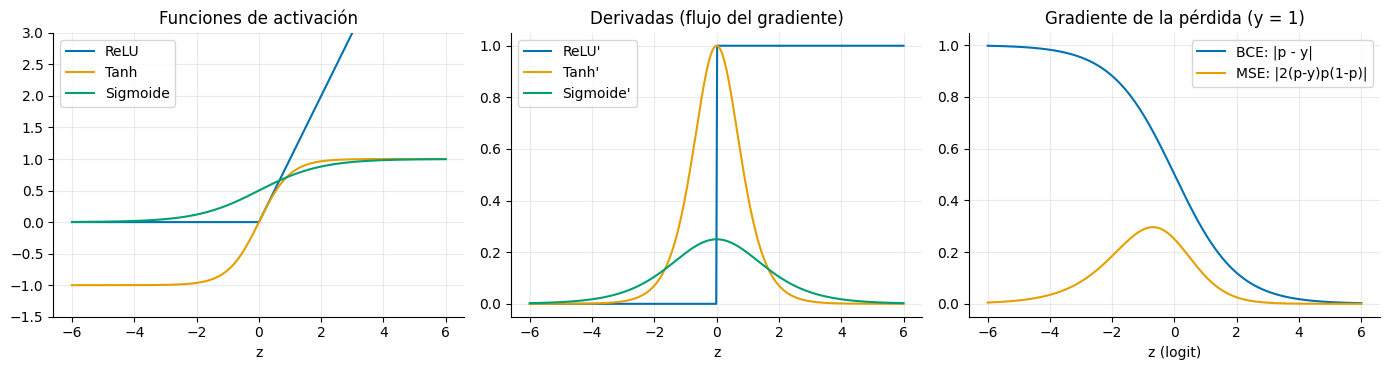

In [5]:
z = np.linspace(-6, 6, 400)
sig = 1 / (1 + np.exp(-z))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].plot(z, np.maximum(0, z), label="ReLU"); ax[0].plot(z, np.tanh(z), label="Tanh"); ax[0].plot(z, sig, label="Sigmoide")
ax[0].set_title("Funciones de activación"); ax[0].set_ylim(-1.5, 3); ax[0].legend(); ax[0].set_xlabel("z")
ax[1].plot(z, (z > 0).astype(float), label="ReLU'"); ax[1].plot(z, 1 - np.tanh(z)**2, label="Tanh'"); ax[1].plot(z, sig*(1-sig), label="Sigmoide'")
ax[1].set_title("Derivadas (flujo del gradiente)"); ax[1].legend(); ax[1].set_xlabel("z")
ax[2].plot(z, 1 - sig, label="BCE: |p - y|"); ax[2].plot(z, 2*sig*(1-sig)**2, label="MSE: |2(p-y)p(1-p)|")
ax[2].set_title("Gradiente de la pérdida (y = 1)"); ax[2].legend(); ax[2].set_xlabel("z (logit)")
plt.tight_layout(); plt.show()

**Métricas** (clase positiva `yes`; TP, FP, FN, TN de la matriz de confusión):

$$\text{Accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{Precision}=\frac{TP}{TP+FP}\qquad \text{Recall}=\frac{TP}{TP+FN}\qquad F1=\frac{2\cdot P\cdot R}{P+R}$$

- **Precision:** de los clientes a quienes se llama, qué fracción contrata (costo de llamadas inútiles).
- **Recall:** de los clientes que contratarían, qué fracción se detecta (costo de oportunidades perdidas).
- **F1:** media armónica; penaliza que una de las dos sea baja.
- **ROC-AUC:** calidad del ranking de probabilidades, independiente del umbral.
- **F1 óptimo:** mejor F1 al variar el umbral en validación; separa la calidad del modelo de la calibración del umbral 0,5.

In [6]:
UMBRALES = np.arange(0.05, 0.96, 0.01)

def calcular_metricas(y_real, prob, umbral=0.50):
    prob = np.asarray(prob).reshape(-1)
    pred = (prob >= umbral).astype(int)
    return {"Accuracy": accuracy_score(y_real, pred),
            "Precision": precision_score(y_real, pred, zero_division=0),
            "Recall": recall_score(y_real, pred, zero_division=0),
            "F1": f1_score(y_real, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_real, prob)}

def mejor_umbral(y_real, prob):
    # Umbral que maximiza F1 (F1 = 2TP / (2TP + FP + FN)), calculado de forma vectorizada.
    pred = np.asarray(prob).reshape(-1, 1) >= UMBRALES.reshape(1, -1)
    y_ = np.asarray(y_real).reshape(-1, 1)
    tp = (pred & (y_ == 1)).sum(0); fp = pred.sum(0) - tp; fn = y_.sum() - tp
    f1 = 2 * tp / np.clip(2 * tp + fp + fn, 1, None)
    i = int(np.argmax(f1))
    return float(UMBRALES[i]), float(f1[i])

# Referencia: clasificador trivial "siempre no"
ref = calcular_metricas(y_val_np, np.zeros(len(y_val_np)) + 1e-6)
print("Clasificador trivial 'siempre no' (validación):",
      {k: round(v, 3) for k, v in ref.items() if k != "ROC_AUC"})

Clasificador trivial 'siempre no' (validación): {'Accuracy': 0.883, 'Precision': 0.0, 'Recall': 0.0, 'F1': 0.0}


## 7. Implementación del MLP

`construir_mlp` arma `Dense → [BatchNorm] → Activación → [Dropout]` por cada capa oculta y una salida sigmoide. El optimizador es **Adam** (tasa adaptativa por parámetro; converge de forma robusta con poco ajuste). Si hay Batch Normalization, la capa densa omite el sesgo (`use_bias=False`) porque BN ya aporta su propio desplazamiento.

`entrenar` recibe solo **los cambios respecto a la configuración base**, lo que garantiza experimentos controlados (un parámetro a la vez) y deja registro de cada prueba. La curva de pérdida de validación y `EarlyStopping` (paciencia 3, restaura los mejores pesos) se usan para detectar sobreajuste.

In [7]:
BASE = dict(activacion="relu", perdida="binary_crossentropy", lr=0.001, batch=256,
            epocas=20, capas=(64, 32), dropout=0.0, bn=False, l2=0.0, es=True)

def construir_mlp(n_entradas, cfg, semilla=SEMILLA):
    tf.keras.backend.clear_session()
    fijar_semilla(semilla)
    m = Sequential([Input(shape=(n_entradas,))])
    for n in cfg["capas"]:
        m.add(Dense(n, use_bias=not cfg["bn"],
                    kernel_regularizer=l2(cfg["l2"]) if cfg["l2"] > 0 else None))
        if cfg["bn"]:
            m.add(BatchNormalization())
        m.add(Activation(cfg["activacion"]))
        if cfg["dropout"] > 0:
            m.add(Dropout(cfg["dropout"]))
    m.add(Dense(1, activation="sigmoid"))
    m.compile(optimizer=Adam(learning_rate=cfg["lr"]), loss=cfg["perdida"])
    return m

modelos, historias, prob_val, registros = {}, {}, {}, []

def entrenar(nombre, grupo, etiqueta, semilla=SEMILLA, guardar=True, **cambios):
    cfg = {**BASE, **cambios}
    modelo = construir_mlp(X_train_proc.shape[1], cfg, semilla)
    cb = [EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)] if cfg["es"] else []
    h = modelo.fit(X_train_proc, y_train_np, validation_data=(X_val_proc, y_val_np),
                   epochs=cfg["epocas"], batch_size=cfg["batch"], class_weight=pesos_clase,
                   callbacks=cb, verbose=0).history
    p = modelo.predict(X_val_proc, verbose=0).ravel()
    m = calcular_metricas(y_val_np, p)
    u, f1o = mejor_umbral(y_val_np, p)
    vl = np.array(h["val_loss"])
    reg = {"Nombre": nombre, "Grupo": grupo, "Configuración": etiqueta,
           "Activación": cfg["activacion"], "Pérdida": cfg["perdida"], "LR": cfg["lr"],
           "Batch": cfg["batch"], "Capas": "-".join(map(str, cfg["capas"])), "Dropout": cfg["dropout"],
           "BN": cfg["bn"], "L2": cfg["l2"], "Épocas": len(vl), "Mejor época": int(vl.argmin()) + 1,
           "Val_loss_min": float(vl.min()), "Sobreajuste": float(vl[-1] - vl.min()),
           **{f"Val_{k}": v for k, v in m.items()}, "Val_F1_opt": f1o, "Umbral_opt": u, "_cfg": cfg}
    historias[nombre] = h; prob_val[nombre] = p
    if guardar:
        modelos[nombre] = modelo
    registros.append(reg)
    return reg

def reg_de(nombre):
    return next(r for r in registros if r["Nombre"] == nombre)

COLS = ["Configuración", "Épocas", "Mejor época", "Val_Accuracy", "Val_Precision",
        "Val_Recall", "Val_F1", "Val_ROC_AUC", "Val_F1_opt"]

def comparar(nombres, etiquetas, titulo, relativa=False):
    # Tabla comparativa + curvas de pérdida (izq.) + Precision/Recall/F1 (der.)
    regs = [dict(reg_de(n), Configuración=e) for n, e in zip(nombres, etiquetas)]
    tabla = pd.DataFrame(regs)[COLS].rename(columns=lambda c: c.replace("Val_", ""))
    display(tabla.round(3).style.hide(axis="index"))
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for i, (n, e) in enumerate(zip(nombres, etiquetas)):
        h = historias[n]; ep = np.arange(1, len(h["val_loss"]) + 1)
        v, t = np.array(h["val_loss"]), np.array(h["loss"])
        if relativa:
            v, t = v / t[0], t / t[0]
        ax[0].plot(ep, v, color=COLORES[i], lw=2, label=e)
        ax[0].plot(ep, t, color=COLORES[i], lw=1, ls=":")
    ax[0].set_xlabel("Época"); ax[0].set_ylabel("Pérdida relativa a la época 1" if relativa else "Pérdida")
    ax[0].set_title(f"{titulo}: pérdida (— validación, ··· entrenamiento)"); ax[0].legend()
    x = np.arange(len(nombres)); w = 0.26
    for j, (met, col) in enumerate([("Precision", COLORES[0]), ("Recall", COLORES[1]), ("F1", COLORES[2])]):
        vals = [r[f"Val_{met}"] for r in regs]
        ax[1].bar(x + (j - 1) * w, vals, w, color=col, label=met)
    ax[1].set_xticks(x); ax[1].set_xticklabels(etiquetas, rotation=15, ha="right"); ax[1].set_ylim(0, 1)
    ax[1].set_title(f"{titulo}: métricas en validación (clase yes, umbral 0,5)"); ax[1].legend()
    plt.tight_layout(); plt.show()
    mf = max(regs, key=lambda r: r["Val_F1"])
    print(f"Mayor F1: {mf['Configuración']} ({mf['Val_F1']:.3f}) | rango de F1 entre configuraciones: "
          f"{max(r['Val_F1'] for r in regs) - min(r['Val_F1'] for r in regs):.3f}")

def estabilidad(nombres, etiquetas):
    filas = []
    for n, e in zip(nombres, etiquetas):
        v = np.array(historias[n]["val_loss"]); r = reg_de(n)
        filas.append({"Configuración": e, "Pérdida val. mínima": v.min(), "Mejor época": int(v.argmin()) + 1,
                      "Aumento tras el mínimo": v[-1] - v.min(),
                      "Oscilación (desv. últimas 5 épocas)": v[-5:].std()})
    display(pd.DataFrame(filas).round(4).style.hide(axis="index"))

## 8. Modelo base

| Parámetro | Valor | Justificación |
|---|---|---|
| Capas ocultas | 64 → 32 | Embudo moderado para ≈ 50 entradas y 27 mil muestras |
| Activación / salida | ReLU / sigmoide | ReLU no satura para z > 0; sigmoide entrega probabilidad |
| Pérdida | Binary Crossentropy | Verosimilitud de un modelo Bernoulli |
| Optimizador, tasa | Adam, 0,001 | Valor estándar estable |
| Batch, épocas | 256, 20 (+ EarlyStopping) | Compromiso velocidad/ruido del gradiente |

Es el **punto de comparación**: cada experimento posterior cambia un solo elemento.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,377 (21.00 KB)

 Trainable params: 5,377 (21.00 KB)

 Non-trainable params: 0 (0.00 B)

Configuración,Épocas,Mejor época,Accuracy,Precision,Recall,F1,ROC_AUC,F1_opt
Base,20,20,0.830000,0.364000,0.598000,0.452000,0.791000,0.491000


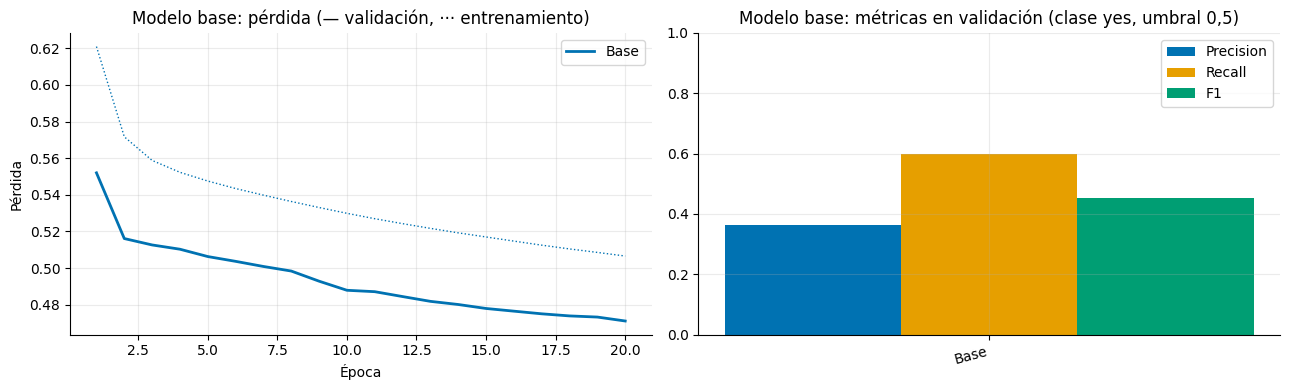

Mayor F1: Base (0.452) | rango de F1 entre configuraciones: 0.000


In [8]:
entrenar("Modelo_base", "Base", "Base")
construir_mlp(X_train_proc.shape[1], BASE).summary()
comparar(["Modelo_base"], ["Base"], "Modelo base")

## 9. Experimentos controlados

Cada experimento modifica **un único parámetro** respecto al modelo base y todo lo demás permanece igual. Se reporta una tabla con las métricas en validación y las curvas de entrenamiento.

> **Nota de lectura:** el F1 a umbral 0,5 depende de la inicialización (en la sección 11.2 el modelo base pasa de F1 = 0,45 con semilla 42 a 0,41 en promedio de otras 5 semillas) y de cómo se calibran las probabilidades. Por eso, además de F1, se reporta **ROC-AUC** y **F1 óptimo**, que miden la capacidad de discriminar independientemente del umbral. Diferencias pequeñas (< ≈ 0,01–0,02) no se interpretan como mejoras.

### 9.1 Funciones de activación (ReLU vs Tanh vs Sigmoide)

Configuración,Épocas,Mejor época,Accuracy,Precision,Recall,F1,ROC_AUC,F1_opt
ReLU (base),20,20,0.830000,0.364000,0.598000,0.452000,0.791000,0.491000
Tanh,6,3,0.811000,0.326000,0.574000,0.416000,0.779000,0.461000
Sigmoide,9,6,0.764000,0.276000,0.626000,0.383000,0.771000,0.449000


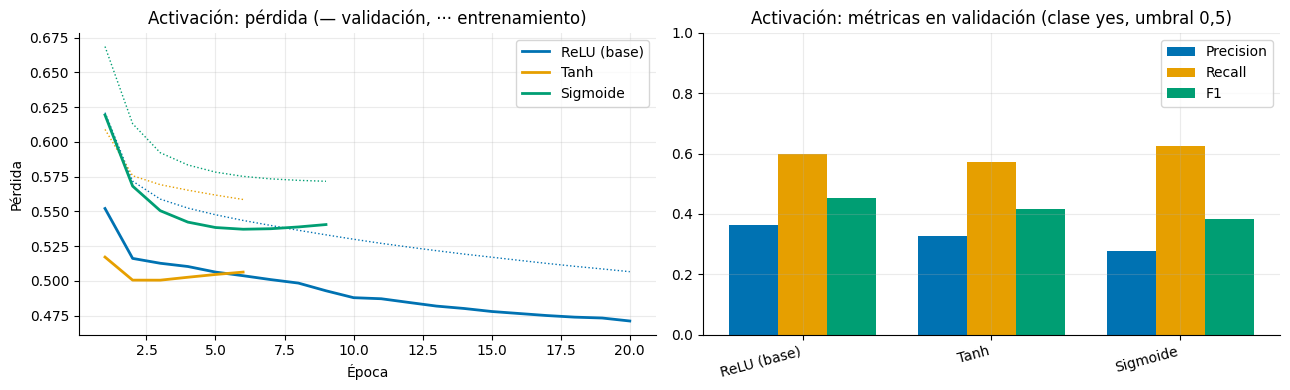

Mayor F1: ReLU (base) (0.452) | rango de F1 entre configuraciones: 0.070


In [9]:
entrenar("Act_tanh", "Activación", "Tanh", activacion="tanh")
entrenar("Act_sigmoid", "Activación", "Sigmoide", activacion="sigmoid")
comparar(["Modelo_base", "Act_tanh", "Act_sigmoid"], ["ReLU (base)", "Tanh", "Sigmoide"], "Activación")

**Análisis (semilla 42).** ReLU obtuvo el mayor F1 (0,452) y el mayor ROC-AUC (0,791), frente a Tanh (0,416 / 0,779) y Sigmoide (0,383 / 0,771). Tanh y Sigmoide alcanzan su mínimo de pérdida de validación antes (épocas 3 y 6) y `EarlyStopping` los detiene, mientras ReLU sigue mejorando hasta la época 20. Sigmoide, con derivada máxima 0,25 y saturación en ambos extremos (sección 6), tiene la menor Precision (0,276) y el menor ROC-AUC, resultado consistente con la atenuación del gradiente. **Decisión:** se mantiene **ReLU**.

### 9.2 Funciones de pérdida (Binary Crossentropy vs MSE)

Configuración,Épocas,Mejor época,Accuracy,Precision,Recall,F1,ROC_AUC,F1_opt
Binary Crossentropy (base),20,20,0.830000,0.364000,0.598000,0.452000,0.791000,0.491000
MSE,20,20,0.827000,0.359000,0.611000,0.453000,0.793000,0.490000


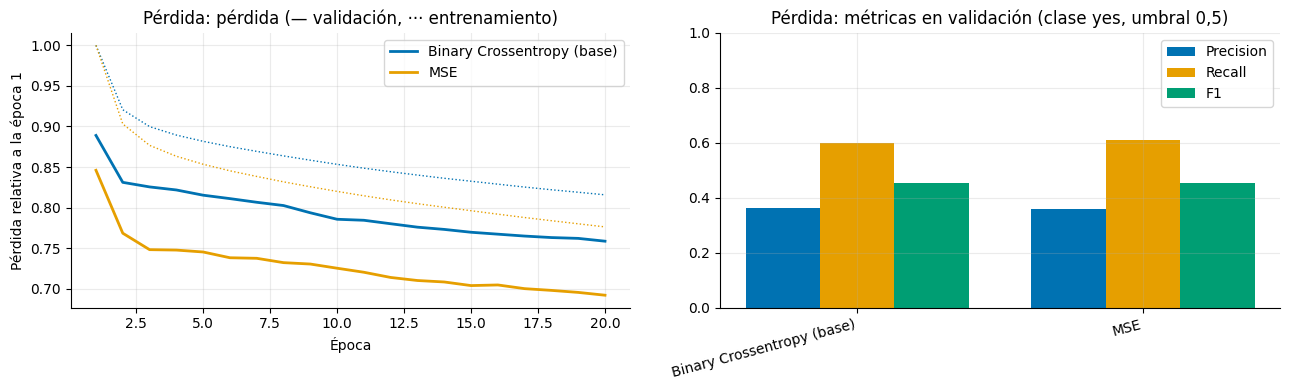

Mayor F1: MSE (0.453) | rango de F1 entre configuraciones: 0.000


In [10]:
entrenar("Perd_mse", "Pérdida", "MSE", perdida="mean_squared_error")
comparar(["Modelo_base", "Perd_mse"], ["Binary Crossentropy (base)", "MSE"], "Pérdida", relativa=True)

**Análisis.** Las métricas son prácticamente iguales (F1 0,452 vs 0,453; ROC-AUC 0,791 vs 0,793; en ambas la mejor época es la 20). Las escalas de las pérdidas no son comparables, por eso el gráfico las normaliza respecto a la época 1. La teoría predice gradientes más débiles para MSE cuando la red está saturada y equivocada (sección 6), pero en este problema no se traduce en una diferencia práctica. **Decisión:** se mantiene **BCE**, coherente con una salida probabilística y que no empeora el resultado.

### 9.3 Tasa de aprendizaje

Configuración,Épocas,Mejor época,Accuracy,Precision,Recall,F1,ROC_AUC,F1_opt
"0,01",4,1,0.831000,0.361000,0.578000,0.444000,0.788000,0.476000
"0,001 (base)",20,20,0.830000,0.364000,0.598000,0.452000,0.791000,0.491000
"0,0001",20,20,0.770000,0.287000,0.650000,0.399000,0.785000,0.463000


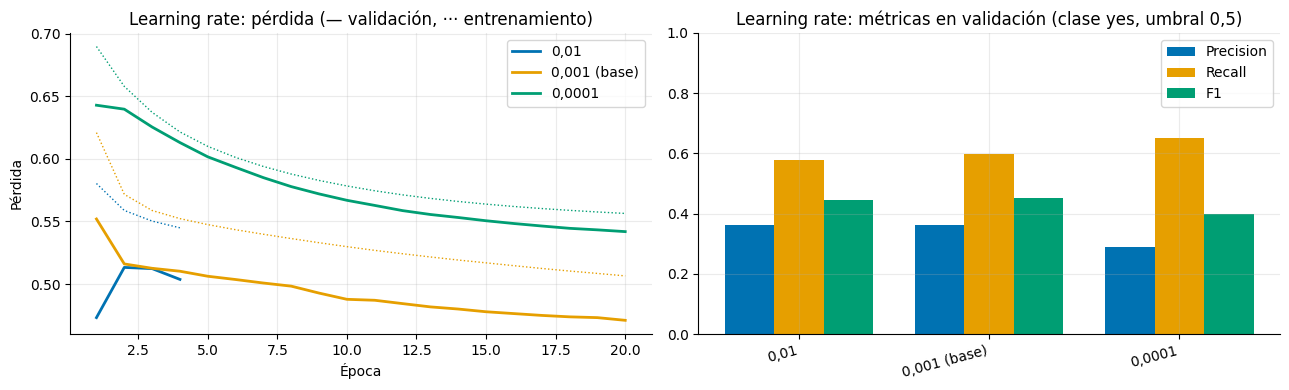

Mayor F1: 0,001 (base) (0.452) | rango de F1 entre configuraciones: 0.054


In [11]:
entrenar("LR_0.01", "Learning rate", "0,01", lr=0.01)
entrenar("LR_0.0001", "Learning rate", "0,0001", lr=0.0001)
comparar(["LR_0.01", "Modelo_base", "LR_0.0001"], ["0,01", "0,001 (base)", "0,0001"], "Learning rate")

**Análisis.** Con **0,01** la pérdida de validación alcanza su mínimo en la **primera época** y el entrenamiento se detiene en la 4.ª: los pasos son demasiado grandes y el modelo sobreajusta de inmediato (F1 0,444; F1 óptimo 0,476). Con **0,0001** la pérdida seguía mejorando en la época 20 (mejor época = 20): no alcanza a converger (F1 0,399; Precision 0,287; F1 óptimo 0,463). **0,001** entrega el mejor resultado (F1 0,452; F1 óptimo 0,491). **Decisión:** se mantiene 0,001; en la sección 11 se evalúa 0,0005 junto con otros parámetros.

### 9.4 Tamaño del batch

Configuración,Épocas,Mejor época,Accuracy,Precision,Recall,F1,ROC_AUC,F1_opt
64,11,8,0.834000,0.372000,0.605000,0.461000,0.793000,0.491000
256 (base),20,20,0.830000,0.364000,0.598000,0.452000,0.791000,0.491000
512,19,16,0.799000,0.323000,0.660000,0.434000,0.796000,0.487000


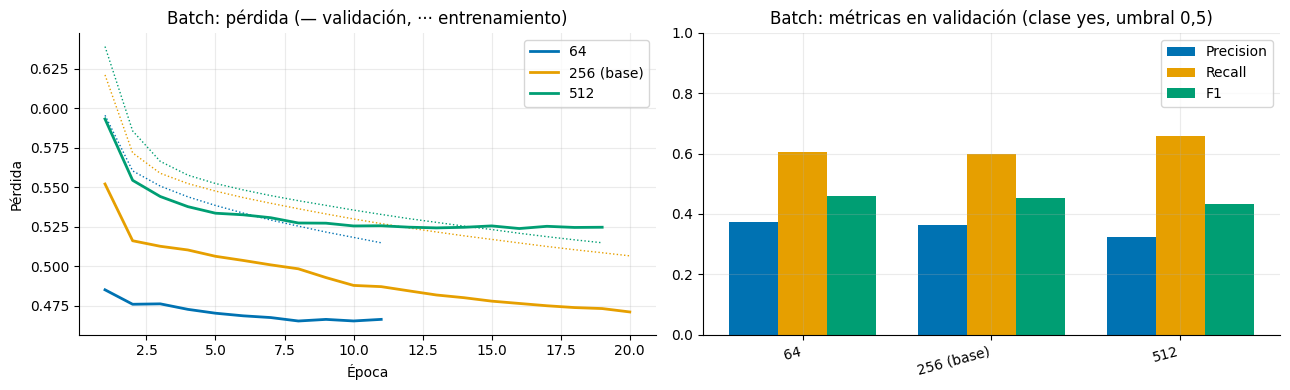

Mayor F1: 64 (0.461) | rango de F1 entre configuraciones: 0.027


In [12]:
entrenar("Batch_64", "Batch", "64", batch=64)
entrenar("Batch_512", "Batch", "512", batch=512)
comparar(["Batch_64", "Modelo_base", "Batch_512"], ["64", "256 (base)", "512"], "Batch")

**Análisis.** Batch **64** obtiene el mayor F1 a 0,5 (0,461) y se detiene antes (mejor época 8), pero su **F1 óptimo es igual al del base (0,491)** y el de 512 es 0,487: el tamaño de batch modifica sobre todo la calibración de las probabilidades (512 sube el Recall a 0,660 con menor Precision), no la capacidad de discriminar (ROC-AUC 0,793 / 0,791 / 0,796). Un batch menor implica más actualizaciones por época y mayor costo de cómputo, con ganancia marginal. En el ajuste (sección 11) se exploran 64 y 128.

### 9.5 Número de épocas
Se desactiva `EarlyStopping` para que cada prueba complete exactamente las épocas indicadas.

Configuración,Épocas,Mejor época,Accuracy,Precision,Recall,F1,ROC_AUC,F1_opt
5 épocas,5,5,0.812000,0.334000,0.614000,0.433000,0.791000,0.470000
15 épocas,15,15,0.830000,0.363000,0.605000,0.454000,0.793000,0.492000
30 épocas,30,27,0.829000,0.360000,0.595000,0.448000,0.787000,0.485000


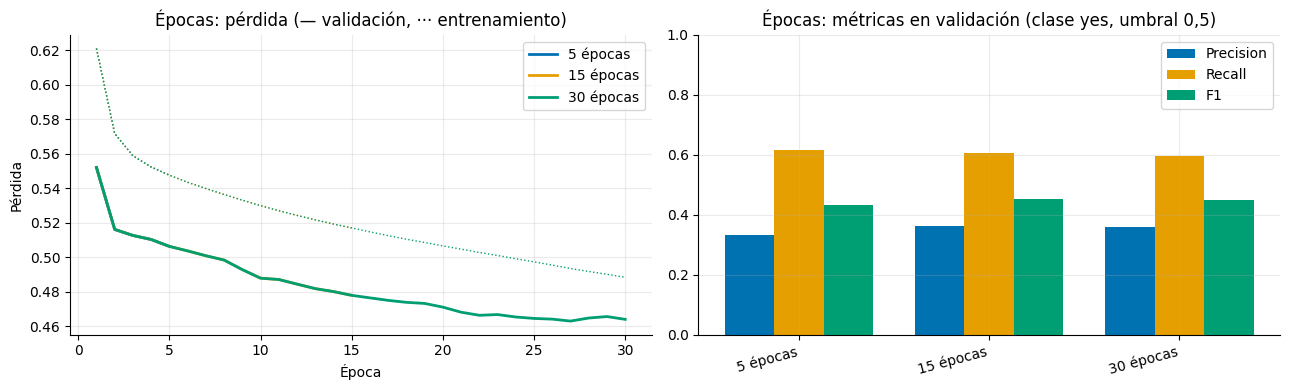

Mayor F1: 15 épocas (0.454) | rango de F1 entre configuraciones: 0.021


Configuración,Pérdida val. mínima,Mejor época,Aumento tras el mínimo,Oscilación (desv. últimas 5 épocas)
5 épocas,0.506300,5,0.000000,0.016600
15 épocas,0.477900,15,0.000000,0.003200
30 épocas,0.463000,27,0.001000,0.000900


In [13]:
for e in (5, 15, 30):
    entrenar(f"Epocas_{e}", "Épocas", f"{e} épocas", epocas=e, es=False)
comparar(["Epocas_5", "Epocas_15", "Epocas_30"], ["5 épocas", "15 épocas", "30 épocas"], "Épocas")
estabilidad(["Epocas_5", "Epocas_15", "Epocas_30"], ["5 épocas", "15 épocas", "30 épocas"])

**Análisis.** Con **5 épocas** el modelo queda subajustado (F1 0,433; F1 óptimo 0,470). Con 15 y 30 épocas el F1 se estabiliza (0,454 y 0,448): la pérdida de validación aún baja levemente (0,478 → 0,463) sin efecto visible en las métricas, y no hay sobreajuste relevante (aumento tras el mínimo ≈ 0,001; mejor época 27 de 30). **Decisión:** fijar un máximo de épocas holgado con `EarlyStopping`, que detiene el entrenamiento si la validación empeora.

### 9.6 Arquitectura (número de capas y neuronas)

Configuración,Épocas,Mejor época,Accuracy,Precision,Recall,F1,ROC_AUC,F1_opt
32,20,20,0.792000,0.313000,0.653000,0.424000,0.793000,0.489000
64-32 (base),20,20,0.830000,0.364000,0.598000,0.452000,0.791000,0.491000
128-64-32,14,11,0.832000,0.363000,0.581000,0.447000,0.788000,0.478000


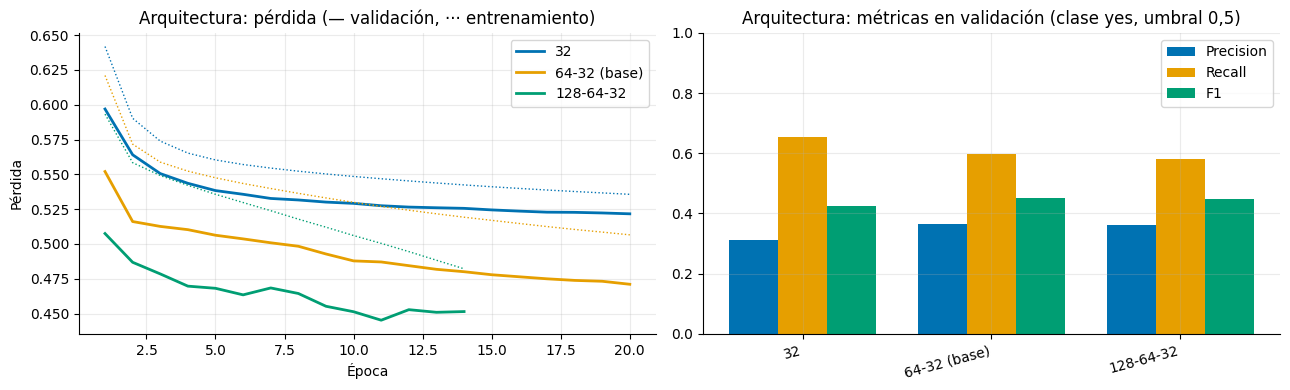

Mayor F1: 64-32 (base) (0.452) | rango de F1 entre configuraciones: 0.029


In [14]:
entrenar("Arq_32", "Arquitectura", "32", capas=(32,))
entrenar("Arq_128_64_32", "Arquitectura", "128-64-32", capas=(128, 64, 32))
comparar(["Arq_32", "Modelo_base", "Arq_128_64_32"], ["32", "64-32 (base)", "128-64-32"], "Arquitectura")

**Análisis.** A umbral 0,5 la red de 32 neuronas rinde menos (F1 0,424), pero su **F1 óptimo (0,489) es casi igual al del base (0,491)**: la diferencia es de calibración (más Recall, menos Precision), no de capacidad de discriminación. La red 128-64-32 no mejora (F1 óptimo 0,478) y alcanza su mínimo de validación antes (época 11; se detiene en la 14), es decir, sobreajusta más rápido. Con variables tabulares y señal limitada, aumentar la capacidad no es la palanca. **Decisión:** mantener 64-32 como base y probar 128-64-32 solo con dropout (sección 11).

## 10. Optimización y regularización

Técnicas para reducir el sobreajuste y estabilizar el entrenamiento:

- **Dropout (0,3):** apaga aleatoriamente 30 % de las neuronas en cada paso; evita co-adaptación.
- **Batch Normalization:** normaliza activaciones por mini-batch; estabiliza y permite tasas mayores.
- **L2 (1e-4):** penaliza pesos grandes, suaviza la función aprendida.
- **EarlyStopping:** ya activo en el modelo base; se compara explícitamente contra entrenar 20 épocas sin él.
- **Combinación** de las tres primeras.

Se compara cada técnica **con y sin** ella contra el modelo base.

Configuración,Épocas,Mejor época,Accuracy,Precision,Recall,F1,ROC_AUC,F1_opt
Base,20,20,0.830000,0.364000,0.598000,0.452000,0.791000,0.491000
"Dropout 0,3",18,15,0.811000,0.338000,0.641000,0.442000,0.797000,0.484000
BatchNorm,14,11,0.794000,0.316000,0.650000,0.425000,0.788000,0.491000
L2 1e-4,20,20,0.834000,0.371000,0.602000,0.459000,0.792000,0.492000
Sin EarlyStopping,20,20,0.830000,0.364000,0.598000,0.452000,0.791000,0.491000
Dropout+BN+L2,10,7,0.778000,0.297000,0.657000,0.409000,0.790000,0.476000


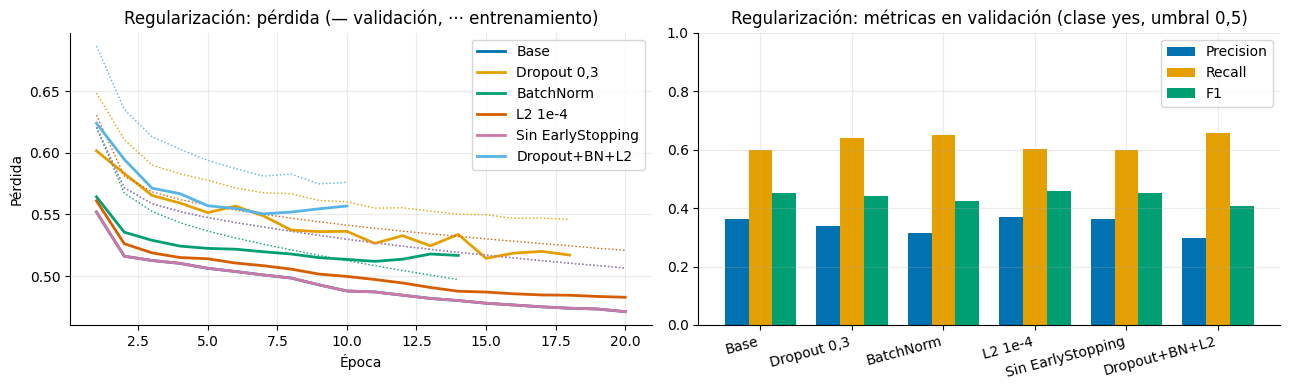

Mayor F1: L2 1e-4 (0.459) | rango de F1 entre configuraciones: 0.050
Estabilidad del entrenamiento (pérdida de validación):


Configuración,Pérdida val. mínima,Mejor época,Aumento tras el mínimo,Oscilación (desv. últimas 5 épocas)
Base,0.471100,20,0.000000,0.001800
"Dropout 0,3",0.514400,15,0.002700,0.006800
BatchNorm,0.511900,11,0.004800,0.002200
L2 1e-4,0.482700,20,0.000000,0.001000
Sin EarlyStopping,0.471100,20,0.000000,0.001800
Dropout+BN+L2,0.550500,7,0.006400,0.002300


In [15]:
entrenar("Reg_dropout", "Regularización", "Dropout 0,3", dropout=0.3)
entrenar("Reg_bn", "Regularización", "BatchNorm", bn=True)
entrenar("Reg_l2", "Regularización", "L2 1e-4", l2=1e-4)
entrenar("Reg_sin_es", "Regularización", "Sin EarlyStopping", es=False)
entrenar("Reg_combo", "Regularización", "Dropout+BN+L2", dropout=0.3, bn=True, l2=1e-4)
n_reg = ["Modelo_base", "Reg_dropout", "Reg_bn", "Reg_l2", "Reg_sin_es", "Reg_combo"]
e_reg = ["Base", "Dropout 0,3", "BatchNorm", "L2 1e-4", "Sin EarlyStopping", "Dropout+BN+L2"]
comparar(n_reg, e_reg, "Regularización")
print("Estabilidad del entrenamiento (pérdida de validación):")
estabilidad(n_reg, e_reg)

**Análisis.** Ninguna técnica mejoró de forma relevante al base (F1 0,452; F1 óptimo 0,491). **L2 1e-4** fue levemente superior a 0,5 (F1 0,459) y **Dropout** obtuvo el mayor ROC-AUC (0,797), pero ambas diferencias son pequeñas; **BatchNorm** (0,425) y la **combinación** (0,409) bajaron el F1 a 0,5 porque aumentaron el Recall (hasta 0,657) a costa de la Precision. `Sin EarlyStopping` es idéntico al base porque el base nunca activó el criterio de parada (mejor época = 20 = máximo de épocas).

La tabla de estabilidad explica el resultado: el modelo base **no sobreajusta** en 20 épocas (su pérdida de validación sigue bajando; aumento tras el mínimo = 0), con ≈ 5 mil parámetros para 27 mil muestras. Dropout, BatchNorm y la combinación alcanzan su mínimo antes (épocas 15, 11 y 7) y luego la pérdida sube levemente (0,003–0,006), por lo que no aportan estabilidad adicional en este modelo. La pérdida mínima no es estrictamente comparable entre configuraciones porque cada una calibra las probabilidades de forma distinta; lo relevante es la forma de la curva (época del mínimo y aumento posterior).

## 11. Análisis de hiperparámetros y reentrenamiento

### 11.1 Búsqueda conjunta
Los experimentos individuales muestran dónde está la sensibilidad (tasa de aprendizaje, batch, arquitectura) y que más épocas o más capas por sí solas no ayudan. Se hace una búsqueda en grilla **pequeña y justificada** (12 combinaciones, hasta 40 épocas con `EarlyStopping`):

| Hiperparámetro | Valores | Motivo |
|---|---|---|
| Learning rate | 0,001; 0,0005 | 0,001 fue el mejor; 0,0005 da pasos más finos |
| Batch | 64; 128 | 64 fue el mejor, 128 reduce costo |
| Dropout | 0; 0,3 | Verificar si ayuda al combinarse con otros cambios |
| Capas | 64-32; 128-64-32 | Mayor capacidad solo **con** dropout (sin regularizar no aportó en 9.6) |

**Criterio de selección:** F1 óptimo en **validación** (mejor F1 al variar el umbral), porque el umbral se calibrará igualmente al final; así no se confunde calidad del modelo con calibración de 0,5. Prueba no interviene.

In [16]:
grilla = [g for g in itertools.product([0.001, 0.0005], [64, 128], [0.0, 0.3], [(64, 32), (128, 64, 32)])
          if not (g[3] == (128, 64, 32) and g[2] == 0.0)]   # 128-64-32 solo con dropout (9.6: sin ventaja sin regularizar)
for lr, b, d, c in grilla:
    cap = "-".join(map(str, c))
    entrenar(f"Ajuste_lr{lr:g}_b{b}_d{d:g}_{cap}", "Ajuste", f"lr={lr:g}, b={b}, d={d:g}, {cap}",
             lr=lr, batch=b, dropout=d, capas=c, epocas=40)

aj = pd.DataFrame([r for r in registros if r["Grupo"] == "Ajuste"])
aj = aj.sort_values(["Val_F1_opt", "Val_ROC_AUC"], ascending=False).reset_index(drop=True)
cols = ["Configuración", "Épocas", "Val_Precision", "Val_Recall", "Val_F1", "Val_ROC_AUC", "Val_F1_opt", "Umbral_opt"]
display(aj[cols].head(8).round(3).style.hide(axis="index"))
nombre_ajustado = aj.loc[0, "Nombre"]
print("Configuración ajustada:", aj.loc[0, "Configuración"])

Configuración,Épocas,Val_Precision,Val_Recall,Val_F1,Val_ROC_AUC,Val_F1_opt,Umbral_opt
"lr=0.001, b=64, d=0.3, 128-64-32",11,0.373000,0.611000,0.463000,0.793000,0.494000,0.610000
"lr=0.0005, b=64, d=0.3, 128-64-32",11,0.357000,0.606000,0.449000,0.792000,0.492000,0.600000
"lr=0.001, b=64, d=0, 64-32",11,0.372000,0.605000,0.461000,0.793000,0.491000,0.610000
"lr=0.0005, b=64, d=0, 64-32",33,0.361000,0.606000,0.452000,0.789000,0.490000,0.650000
"lr=0.001, b=128, d=0, 64-32",25,0.362000,0.621000,0.457000,0.790000,0.487000,0.670000
"lr=0.0005, b=128, d=0.3, 128-64-32",13,0.339000,0.614000,0.437000,0.791000,0.486000,0.610000
"lr=0.001, b=128, d=0.3, 64-32",14,0.326000,0.637000,0.431000,0.797000,0.485000,0.670000
"lr=0.0005, b=64, d=0.3, 64-32",17,0.339000,0.634000,0.442000,0.796000,0.484000,0.640000


Configuración ajustada: lr=0.001, b=64, d=0.3, 128-64-32


### 11.2 Robustez: base vs ajustado con 5 semillas
Una sola ejecución puede favorecer a una configuración por azar. Se reentrenan **el modelo base y el ajustado con 5 semillas** y se comparan medias y desviaciones en validación.

Val_Precision        Val_Recall        Val_F1        Val_ROC_AUC        Val_F1_opt       
                       mean    std       mean    std   mean    std        mean    std       mean    std
Configuración                                                                                          
Ajustado              0.328  0.011      0.640  0.015  0.433  0.007       0.797  0.002      0.494  0.005
Base                  0.296  0.015      0.671  0.018  0.410  0.012       0.794  0.002      0.490  0.004

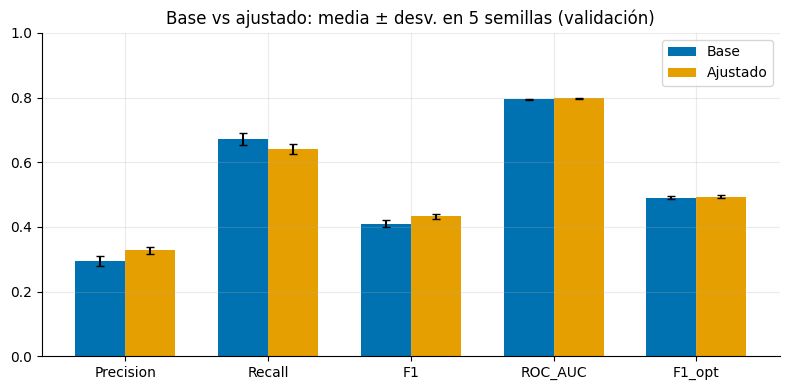

F1 óptimo medio: base 0.490 (±0.004) vs ajustado 0.494 → modelo final: lr=0.001, b=64, d=0.3, 128-64-32
Nota: la diferencia es menor que la desviación entre semillas; la mejora no es concluyente.


In [17]:
SEMILLAS = [11, 22, 33, 44, 55]
cfg_ajustado = {k: v for k, v in reg_de(nombre_ajustado)["_cfg"].items()}
for s in SEMILLAS:
    entrenar(f"Base_s{s}", "Semillas", "Base", semilla=s, guardar=False)
    entrenar(f"Ajustado_s{s}", "Semillas", "Ajustado", semilla=s, guardar=False, **cfg_ajustado)

sem = pd.DataFrame([r for r in registros if r["Grupo"] == "Semillas"])
mets = ["Val_Precision", "Val_Recall", "Val_F1", "Val_ROC_AUC", "Val_F1_opt"]
resumen = sem.groupby("Configuración")[mets].agg(["mean", "std"]).round(3)
display(resumen)

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(mets)); w = 0.35
for i, c in enumerate(["Base", "Ajustado"]):
    sub = sem[sem["Configuración"] == c]
    ax.bar(x + (i - 0.5) * w, sub[mets].mean(), w, yerr=sub[mets].std(), capsize=3, color=COLORES[i], label=c)
ax.set_xticks(x); ax.set_xticklabels([m.replace("Val_", "") for m in mets]); ax.set_ylim(0, 1)
ax.set_title("Base vs ajustado: media ± desv. en 5 semillas (validación)"); ax.legend()
plt.tight_layout(); plt.show()

m_b = sem[sem["Configuración"] == "Base"]["Val_F1_opt"].mean()
m_a = sem[sem["Configuración"] == "Ajustado"]["Val_F1_opt"].mean()
s_b = sem[sem["Configuración"] == "Base"]["Val_F1_opt"].std()
nombre_final = nombre_ajustado if m_a > m_b else "Modelo_base"
print(f"F1 óptimo medio: base {m_b:.3f} (±{s_b:.3f}) vs ajustado {m_a:.3f} → modelo final: {reg_de(nombre_final)['Configuración']}")
if abs(m_a - m_b) < s_b:
    print("Nota: la diferencia es menor que la desviación entre semillas; la mejora no es concluyente.")

**Lectura.** Con 5 semillas (validación), el ajustado supera al base en **F1 a 0,5** (0,433 ± 0,007 vs 0,410 ± 0,012; Precision 0,328 vs 0,296), diferencia mayor que la desviación entre semillas. En cambio, en **F1 óptimo** (0,494 vs 0,490) y **ROC-AUC** (0,797 vs 0,794) la ventaja es comparable a la desviación (≈ 0,004 y 0,002): el ajuste mejora sobre todo la Precision y la calibración a umbral 0,5, y apenas la capacidad de discriminación. Además, el F1 a 0,5 del base con semilla 42 (0,452) es mayor que su promedio en estas 5 semillas (0,410), por lo que las comparaciones basadas en una sola semilla deben interpretarse con cautela.

### Con y sin optimización: efecto en estabilidad

Configuración,Épocas,Mejor época,Accuracy,Precision,Recall,F1,ROC_AUC,F1_opt
Base (sin optimización),20,20,0.830000,0.364000,0.598000,0.452000,0.791000,0.491000
Ajustado (dropout/batch/lr/EarlyStopping),11,8,0.834000,0.373000,0.611000,0.463000,0.793000,0.494000


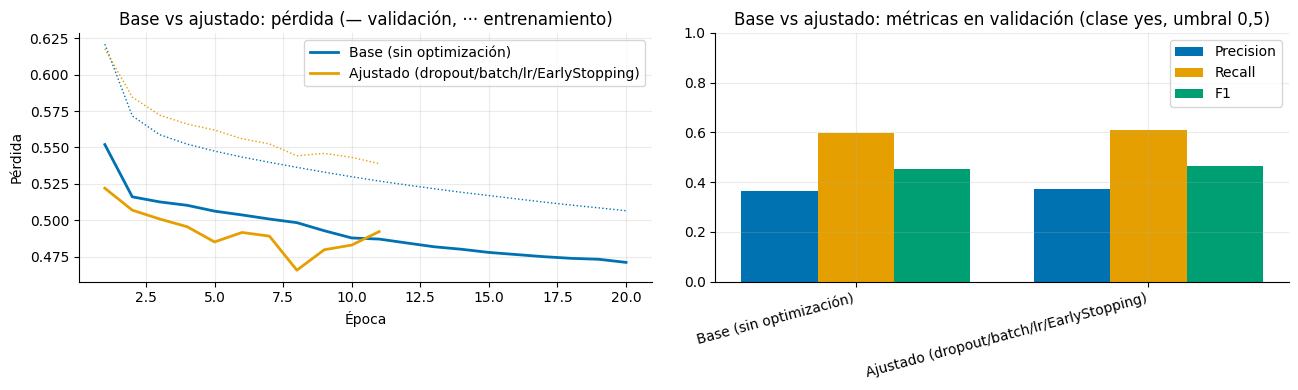

Mayor F1: Ajustado (dropout/batch/lr/EarlyStopping) (0.463) | rango de F1 entre configuraciones: 0.011


Configuración,Pérdida val. mínima,Mejor época,Aumento tras el mínimo,Oscilación (desv. últimas 5 épocas)
Base (sin optimización),0.471100,20,0.000000,0.001800
Ajustado (dropout/batch/lr/EarlyStopping),0.465700,8,0.026500,0.009200


In [18]:
par = ["Modelo_base", nombre_ajustado]
etq = ["Base (sin optimización)", "Ajustado (dropout/batch/lr/EarlyStopping)"]
comparar(par, etq, "Base vs ajustado")
estabilidad(par, etq)

**Análisis.** El modelo ajustado alcanza su mínimo de validación en la época 8 (pérdida 0,466 vs 0,471 del base) y `EarlyStopping` restaura esos pesos; el aumento de 0,027 posterior corresponde a las 3 épocas de paciencia. El base, en cambio, termina por límite de épocas (20) sin haber sobreajustado. La red mayor con dropout aprende más rápido y requiere detención temprana; el beneficio práctico es moderado (F1 0,463 vs 0,452; F1 óptimo 0,494 vs 0,491).

### 11.3 Verificación de la decisión sobre `duration`
Se reentrena el modelo base **incluyendo** `duration` para cuantificar la fuga de información que se evitó.

In [19]:
D2 = preparar(excluir=["y"])
cfg_b = dict(BASE)
m_leak = construir_mlp(D2["X_tr"].shape[1], cfg_b)
m_leak.fit(D2["X_tr"], D2["y_tr"], validation_data=(D2["X_va"], D2["y_va"]), epochs=cfg_b["epocas"],
           batch_size=cfg_b["batch"], class_weight=pesos_clase, verbose=0,
           callbacks=[EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)])
p_leak = m_leak.predict(D2["X_va"], verbose=0).ravel()
comp = pd.DataFrame({"Sin duration (usado)": calcular_metricas(y_val_np, prob_val["Modelo_base"]),
                     "Con duration (fuga)": calcular_metricas(D2["y_va"], p_leak)})
display(comp.round(3))

,Sin duration (usado),Con duration (fuga)
Accuracy,0.830,0.867
Precision,0.364,0.463
Recall,0.598,0.849
F1,0.452,0.599
ROC_AUC,0.791,0.933


Si las métricas con `duration` son claramente superiores, esa mejora **no es real**: se obtiene con información que no existe antes de llamar. Se confirma la exclusión.

## 12. Evaluación final

### 12.1 Umbral de decisión (solo validación)
El `class_weight` desplaza las probabilidades; el umbral 0,5 no es necesariamente el mejor. Se elige en validación el que maximiza F1 y se **fija antes** de mirar prueba. Subir el umbral aumenta Precision y reduce Recall; bajarlo hace lo contrario: es la palanca directa para ajustar el compromiso según el costo de llamar vs perder un cliente.

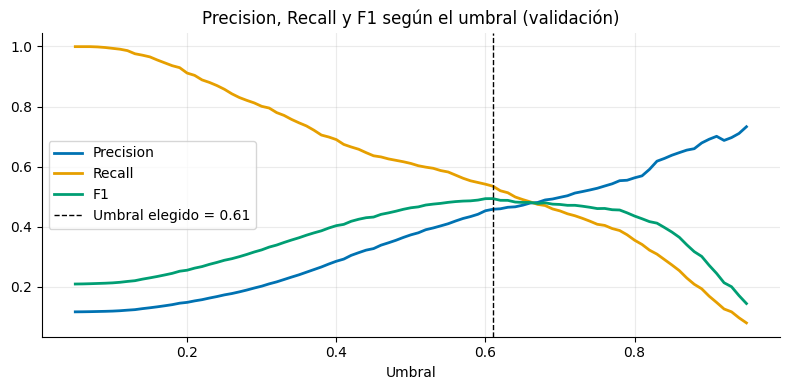

Modelo final: lr=0.001, b=64, d=0.3, 128-64-32 | umbral = 0.61 | F1 validación = 0.494


In [20]:
modelo_final = modelos[nombre_final]
p_val = prob_val[nombre_final]
umbral_final, f1_val_opt = mejor_umbral(y_val_np, p_val)

curva = pd.DataFrame([{"Umbral": u, **{k: v for k, v in calcular_metricas(y_val_np, p_val, u).items()}} for u in UMBRALES])
fig, ax = plt.subplots(figsize=(8, 4))
for col, c in zip(["Precision", "Recall", "F1"], COLORES):
    ax.plot(curva["Umbral"], curva[col], color=c, lw=2, label=col)
ax.axvline(umbral_final, color="black", ls="--", lw=1, label=f"Umbral elegido = {umbral_final:.2f}")
ax.set_xlabel("Umbral"); ax.set_title("Precision, Recall y F1 según el umbral (validación)"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Modelo final: {reg_de(nombre_final)['Configuración']} | umbral = {umbral_final:.2f} | F1 validación = {f1_val_opt:.3f}")

### 12.2 Resultados en el conjunto de prueba (una sola evaluación)

CUADRO RESUMEN — conjunto de prueba (clase yes)


,"Base (umbral 0,50)",Base (umbral 0.64),"Final (umbral 0,50)",Final (umbral 0.61)
Accuracy,0.829,0.873,0.830,0.869
Precision,0.360,0.461,0.362,0.446
Recall,0.595,0.486,0.589,0.508
F1,0.449,0.473,0.448,0.475
ROC_AUC,0.779,0.779,0.789,0.789


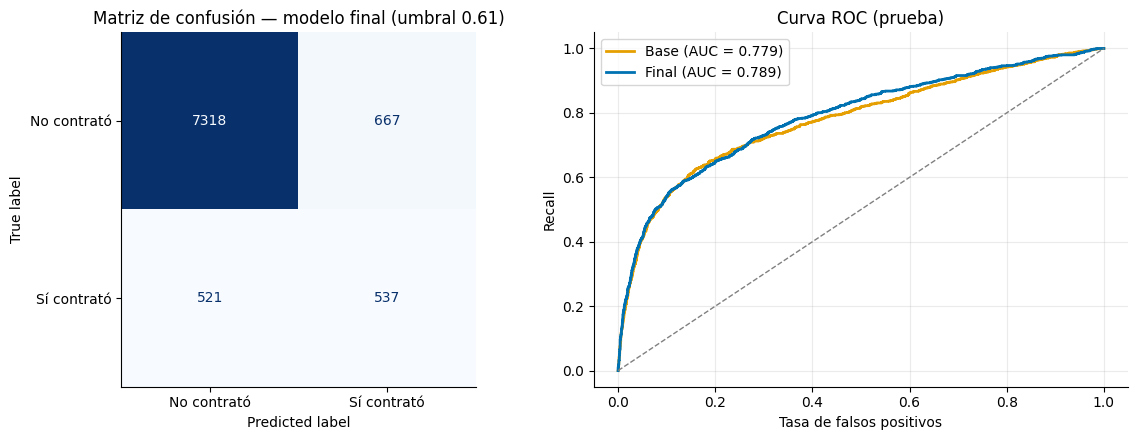

              precision    recall  f1-score   support

 No contrató       0.93      0.92      0.92      7985
 Sí contrató       0.45      0.51      0.47      1058

    accuracy                           0.87      9043
   macro avg       0.69      0.71      0.70      9043
weighted avg       0.88      0.87      0.87      9043

TP=537  FP=667  FN=521  TN=7318
Accuracy  = (537+7318)/9043 = 0.869
Precision = 537/(537+667) = 0.446
Recall    = 537/(537+521) = 0.508
F1        = 2·0.446·0.508/(0.446+0.508) = 0.475


In [21]:
p_te_final = modelo_final.predict(X_test_proc, verbose=0).ravel()
p_te_base = modelos["Modelo_base"].predict(X_test_proc, verbose=0).ravel()
u_base, _ = mejor_umbral(y_val_np, prob_val["Modelo_base"])

resumen_test = pd.DataFrame({
    "Base (umbral 0,50)": calcular_metricas(y_test_np, p_te_base, 0.50),
    f"Base (umbral {u_base:.2f})": calcular_metricas(y_test_np, p_te_base, u_base),
    "Final (umbral 0,50)": calcular_metricas(y_test_np, p_te_final, 0.50),
    f"Final (umbral {umbral_final:.2f})": calcular_metricas(y_test_np, p_te_final, umbral_final)})
print("CUADRO RESUMEN — conjunto de prueba (clase yes)")
display(resumen_test.round(3))

pred = (p_te_final >= umbral_final).astype(int)
cm = confusion_matrix(y_test_np, pred, labels=[0, 1])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["No contrató", "Sí contrató"]).plot(ax=ax[0], cmap="Blues", values_format="d", colorbar=False)
ax[0].set_title(f"Matriz de confusión — modelo final (umbral {umbral_final:.2f})"); ax[0].grid(False)
for p, n, c in [(p_te_base, "Base", COLORES[1]), (p_te_final, "Final", COLORES[0])]:
    fpr, tpr, _ = roc_curve(y_test_np, p)
    ax[1].plot(fpr, tpr, color=c, lw=2, label=f"{n} (AUC = {roc_auc_score(y_test_np, p):.3f})")
ax[1].plot([0, 1], [0, 1], color="gray", ls="--", lw=1); ax[1].set_xlabel("Tasa de falsos positivos")
ax[1].set_ylabel("Recall"); ax[1].set_title("Curva ROC (prueba)"); ax[1].legend()
plt.tight_layout(); plt.show()

print(classification_report(y_test_np, pred, target_names=["No contrató", "Sí contrató"], zero_division=0))

# Cálculo manual de las métricas a partir de la matriz de confusión (verificación)
TN, FP, FN, TP = cm.ravel()
acc = (TP + TN) / cm.sum(); prec = TP / (TP + FP); rec = TP / (TP + FN); f1 = 2 * prec * rec / (prec + rec)
print(f"TP={TP}  FP={FP}  FN={FN}  TN={TN}")
print(f"Accuracy  = ({TP}+{TN})/{cm.sum()} = {acc:.3f}")
print(f"Precision = {TP}/({TP}+{FP}) = {prec:.3f}")
print(f"Recall    = {TP}/({TP}+{FN}) = {rec:.3f}")
print(f"F1        = 2·{prec:.3f}·{rec:.3f}/({prec:.3f}+{rec:.3f}) = {f1:.3f}")
assert np.isclose(f1, f1_score(y_test_np, pred)), "El cálculo manual no coincide con scikit-learn"

### 12.3 Interpretación de las métricas y cómo mejorarlas

In [22]:
cal = lambda c: resumen_test[c]
col_f = f"Final (umbral {umbral_final:.2f})"
print(f"• Accuracy {cal(col_f)['Accuracy']:.3f}: engañosa por el desbalance; el clasificador trivial 'siempre no' llega a {ref['Accuracy']:.3f}.")
print(f"• Precision {cal(col_f)['Precision']:.3f}: de cada 100 clientes a quienes se llama, ≈ {cal(col_f)['Precision']*100:.0f} contratan "
      f"(la tasa base sin modelo es {y_test_np.mean()*100:.1f}%, es decir, el modelo la multiplica por ≈ {cal(col_f)['Precision']/y_test_np.mean():.1f}).")
print(f"• Recall {cal(col_f)['Recall']:.3f}: se detecta ≈ {cal(col_f)['Recall']*100:.0f}% de quienes contratarían; el resto ({FN} clientes) se pierde.")
print(f"• F1 {cal(col_f)['F1']:.3f} y ROC-AUC {cal(col_f)['ROC_AUC']:.3f}: señal predictiva real pero moderada.")
print(f"• Efecto del umbral: el base pasa de F1 {cal('Base (umbral 0,50)')['F1']:.3f} (umbral 0,50) a {cal(f'Base (umbral {u_base:.2f})')['F1']:.3f} (umbral {u_base:.2f}); el final alcanza {cal(col_f)['F1']:.3f}.")

• Accuracy 0.869: engañosa por el desbalance; el clasificador trivial 'siempre no' llega a 0.883.
• Precision 0.446: de cada 100 clientes a quienes se llama, ≈ 45 contratan (la tasa base sin modelo es 11.7%, es decir, el modelo la multiplica por ≈ 3.8).
• Recall 0.508: se detecta ≈ 51% de quienes contratarían; el resto (521 clientes) se pierde.
• F1 0.475 y ROC-AUC 0.789: señal predictiva real pero moderada.
• Efecto del umbral: el base pasa de F1 0.449 (umbral 0,50) a 0.473 (umbral 0.64); el final alcanza 0.475.


**Cómo mejorar Precision y Recall (fundamentado en lo observado):**

1. **Umbral según costo de negocio:** subirlo prioriza Precision (menos llamadas inútiles); bajarlo prioriza Recall (captar más interesados). La curva de la sección 12.1 muestra el compromiso.
2. **Mejor señal, no más capacidad:** la arquitectura mayor no mejoró (sección 9.6); conviene ingeniería de variables (p. ej. indicador "contactado antes" a partir de `pdays`, interacciones mes × resultado previo).
3. **Manejo del desbalance:** probar *focal loss* o sobremuestreo (SMOTE) en lugar de/además de `class_weight`.
4. **Validación más robusta:** validación cruzada estratificada y comparación con un modelo de árboles (p. ej. *gradient boosting*) como referencia en datos tabulares.

## 13. Conclusiones

**Resultados de la fase experimental (semilla 42):**

- **Activación:** ReLU superó a Tanh y Sigmoide (F1 0,452 vs 0,416 y 0,383; ROC-AUC 0,791 vs 0,779 y 0,771); las funciones saturantes alcanzan su mínimo de validación antes (épocas 3 y 6).
- **Pérdida:** BCE y MSE fueron equivalentes (F1 0,452 vs 0,453); se eligió BCE por su coherencia con la salida probabilística.
- **Tasa de aprendizaje:** 0,001 fue la mejor; 0,01 sobreajusta desde la primera época y 0,0001 no converge en 20 épocas.
- **Batch, épocas y arquitectura:** modifican sobre todo la calibración a umbral 0,5; el F1 óptimo se mantiene en 0,47–0,49, sin ganancia relevante con más capacidad ni más épocas.
- **Regularización:** ninguna técnica mejoró de forma relevante al base, que no sobreajusta en 20 épocas.
- **Ajuste conjunto:** la configuración final (lr 0,001; batch 64; dropout 0,3; 128-64-32) mejora el F1 a 0,5 (0,433 vs 0,410 en promedio de 5 semillas), pero la mejora en ROC-AUC y F1 óptimo es marginal.
- **Umbral de decisión:** es la palanca más efectiva; en prueba, solo calibrar el umbral del modelo base eleva el F1 de 0,449 a 0,473.

**Resultado final:**

In [23]:
fb, ff = cal("Base (umbral 0,50)"), cal(col_f)
print(f"Modelo final: {reg_de(nombre_final)['Configuración']} | umbral {umbral_final:.2f} (elegido en validación)")
print(f"Prueba → Accuracy {ff['Accuracy']:.3f} | Precision {ff['Precision']:.3f} | Recall {ff['Recall']:.3f} | "
      f"F1 {ff['F1']:.3f} | ROC-AUC {ff['ROC_AUC']:.3f}")
print(f"Modelo base (umbral 0,50) → F1 {fb['F1']:.3f} | Recall {fb['Recall']:.3f} | Precision {fb['Precision']:.3f}")
print(f"Diferencia de F1 en prueba (final con umbral elegido vs base con 0,50; incluye el efecto del umbral): {ff['F1'] - fb['F1']:+.3f}")

Modelo final: lr=0.001, b=64, d=0.3, 128-64-32 | umbral 0.61 (elegido en validación)
Prueba → Accuracy 0.869 | Precision 0.446 | Recall 0.508 | F1 0.475 | ROC-AUC 0.789
Modelo base (umbral 0,50) → F1 0.449 | Recall 0.595 | Precision 0.360
Diferencia de F1 en prueba (final con umbral elegido vs base con 0,50; incluye el efecto del umbral): +0.026


**Limitaciones:** (1) se excluyó `duration`, por lo que el desempeño es el de un modelo realmente utilizable antes de llamar; (2) el desbalance limita la Precision: incluso el mejor umbral exige aceptar falsos positivos; (3) una única partición 60/20/20; las diferencias pequeñas entre configuraciones están dentro del ruido entre semillas; (4) los datos corresponden a una campaña específica, por lo que se requiere validar con campañas posteriores.

**Mejoras propuestas:** ingeniería de variables, manejo alternativo del desbalance, validación cruzada y comparación con modelos de árboles (sección 12.3).